# CSE428 Spring 26 — Pet Segmentation & Classification
**Oxford-IIIT Pet Dataset | PyTorch | U-Net & Attention U-Net**

---
## 🚨 AFTER A DISCONNECT — DO THIS:
1. Run **Cell 1** — Mount Drive
2. Run **Cell 2** — Full Setup
3. Run **Cell 4** again — it will **auto-resume** from the last saved epoch
---

## Cell 1 — Mount Google Drive

In [ ]:
from google.colab import drive
import os, torch

drive.mount('/content/drive', force_remount=True)

SAVE_DIR      = '/content/drive/MyDrive/CSE428_Project'
os.makedirs(SAVE_DIR, exist_ok=True)

UNET_CKPT = os.path.join(SAVE_DIR, 'unet_checkpoint.pth')
UNET_BEST = os.path.join(SAVE_DIR, 'unet_best.pth')
ATT_CKPT  = os.path.join(SAVE_DIR, 'att_checkpoint.pth')
ATT_BEST  = os.path.join(SAVE_DIR, 'att_best.pth')

# Quick write test
_test = os.path.join(SAVE_DIR, '_write_test.txt')
try:
    with open(_test, 'w') as f: f.write('ok')
    os.remove(_test)
    print('✅ Drive mounted and WRITABLE')
except Exception as e:
    print(f'❌ Drive NOT writable: {e}')

print(f'\nSave dir : {SAVE_DIR}')
for name, p in [('unet_checkpoint', UNET_CKPT), ('unet_best',  UNET_BEST),
                ('att_checkpoint',  ATT_CKPT),  ('att_best',   ATT_BEST)]:
    if os.path.exists(p):
        try:
            ck = torch.load(p, map_location='cpu', weights_only=False)
            ep = ck.get('epoch', '?')
            print(f'  ✅ {name}.pth  (epoch {ep})')
        except:
            print(f'  ✅ {name}.pth  (best weights)')
    else:
        print(f'  📭 {name}.pth — not yet')


Mounted at /content/drive
✅ Drive mounted and WRITABLE

Save dir : /content/drive/MyDrive/CSE428_Project
  ✅ unet_checkpoint.pth  (epoch 30)
  ✅ unet_best.pth  (epoch ?)
  ✅ att_checkpoint.pth  (epoch 30)
  ✅ att_best.pth  (epoch ?)


## Cell 2 — Install + Full Setup *(Run Every Session)*

In [ ]:
import subprocess, sys
subprocess.run([sys.executable,'-m','pip','install','-q','albumentations'], check=True)

# ── Imports ──────────────────────────────────────────────────────────────────
import os, random, urllib.request, tarfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import albumentations as A
from albumentations.pytorch import ToTensorV2
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# ── Config ────────────────────────────────────────────────────────────────────

SEED=42; IMG_SIZE=224; BATCH_SIZE=16; NUM_EPOCHS=30; LR=1e-3
IMAGENET_MEAN=(0.485,0.456,0.406); IMAGENET_STD=(0.229,0.224,0.225)

random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}', end='  |  ')
if DEVICE.type=='cuda':
    print(f'GPU: {torch.cuda.get_device_name(0)}')
    print(f'GPU RAM: {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB')
else: print('No GPU — training will be very slow!')

# ── Dataset paths ─────────────────────────────────────────────────────────────
DATA_DIR   = Path('/content/oxford_pets')
IMAGES_DIR = DATA_DIR/'images'
MASKS_DIR  = DATA_DIR/'annotations'/'trimaps'
LIST_FILE  = DATA_DIR/'annotations'/'list.txt'
DATA_DIR.mkdir(exist_ok=True, parents=True)

def _dl(url, out):
    if not Path(out).exists():
        print(f'Downloading {Path(url).name}...')
        urllib.request.urlretrieve(url, out)
def _ex(tar_path, dest):
    if not Path(dest).exists() or len(list(Path(dest).glob('*')))==0:
        print(f'Extracting {Path(tar_path).name}...')
        with tarfile.open(tar_path) as t: t.extractall(DATA_DIR)

_dl('https://www.robots.ox.ac.uk/~vgg/data/pets/data/images.tar.gz',      DATA_DIR/'images.tar.gz')
_dl('https://www.robots.ox.ac.uk/~vgg/data/pets/data/annotations.tar.gz', DATA_DIR/'annotations.tar.gz')
_ex(DATA_DIR/'images.tar.gz',      IMAGES_DIR)
_ex(DATA_DIR/'annotations.tar.gz', MASKS_DIR.parent)
print(f'Images: {len(list(IMAGES_DIR.glob("*.jpg")))} | Masks: {len(list(MASKS_DIR.glob("*.png")))}')

# ── Metadata ──────────────────────────────────────────────────────────────────
records=[]
with open(LIST_FILE) as f:
    for line in f:
        line=line.strip()
        if line.startswith('#') or not line: continue
        p=line.split()
        records.append({'filename':p[0],'class_id':int(p[1])-1,
            'species':'Cat' if int(p[2])==1 else 'Dog',
            'breed':'_'.join(p[0].split('_')[:-1]),
            'img_path':str(IMAGES_DIR/f'{p[0]}.jpg'),
            'mask_path':str(MASKS_DIR/f'{p[0]}.png')})
df=pd.DataFrame(records)
df=df[df['img_path'].apply(os.path.exists)&df['mask_path'].apply(os.path.exists)].reset_index(drop=True)
NUM_CLASSES=df['class_id'].nunique()
print(f'Samples:{len(df)} | Classes:{NUM_CLASSES} | Cats:{(df.species=="Cat").sum()} | Dogs:{(df.species=="Dog").sum()}')
id2breed  =df.drop_duplicates('class_id').set_index('class_id')['breed'].to_dict()
id2species=df.drop_duplicates('class_id').set_index('class_id')['species'].to_dict()

# ── Helpers ───────────────────────────────────────────────────────────────────
def load_mask_binary(mask_path):
    return np.where(np.array(Image.open(mask_path))==2,0,1).astype(np.uint8)

def make_overlay(img_rgb, mask_bin, color=(0,200,0), alpha=0.5):
    out=img_rgb.copy().astype(float)
    for ci,cv in enumerate(color):
        out[mask_bin==1,ci]=out[mask_bin==1,ci]*(1-alpha)+cv*alpha
    return out.clip(0,255).astype(np.uint8)

# ── Transforms ────────────────────────────────────────────────────────────────
train_tf=A.Compose([A.Resize(IMG_SIZE,IMG_SIZE),A.HorizontalFlip(p=0.5),
    A.RandomRotate90(p=0.3),
    A.ShiftScaleRotate(shift_limit=0.1,scale_limit=0.2,rotate_limit=30,p=0.5),
    A.ColorJitter(brightness=0.3,contrast=0.3,saturation=0.2,hue=0.1,p=0.5),
    A.GaussianBlur(blur_limit=(3,5),p=0.2),
    A.Normalize(mean=IMAGENET_MEAN,std=IMAGENET_STD),ToTensorV2()])
val_tf=A.Compose([A.Resize(IMG_SIZE,IMG_SIZE),
    A.Normalize(mean=IMAGENET_MEAN,std=IMAGENET_STD),ToTensorV2()])

# ── Dataset ───────────────────────────────────────────────────────────────────
class PetDataset(Dataset):
    def __init__(self,dataframe,transform=None):
        self.df=dataframe.reset_index(drop=True); self.transform=transform
    def __len__(self): return len(self.df)
    def __getitem__(self,idx):
        row=self.df.iloc[idx]
        img=np.array(Image.open(row['img_path']).convert('RGB'))
        mask=load_mask_binary(row['mask_path']); label=int(row['class_id'])
        if self.transform:
            out=self.transform(image=img,mask=mask)
            img,mask=out['image'],out['mask'].long()
        return img,mask,label

train_df,temp_df=train_test_split(df,test_size=0.2,random_state=SEED,stratify=df['class_id'])
val_df,test_df  =train_test_split(temp_df,test_size=0.5,random_state=SEED,stratify=temp_df['class_id'])
print(f'Split -> Train:{len(train_df)} | Val:{len(val_df)} | Test:{len(test_df)}')

train_ds=PetDataset(train_df,transform=train_tf)
val_ds  =PetDataset(val_df,  transform=val_tf)
test_ds =PetDataset(test_df, transform=val_tf)
# num_workers=0 avoids DataLoader worker crashes that can kill the runtime
train_loader=DataLoader(train_ds,batch_size=BATCH_SIZE,shuffle=True, num_workers=0,pin_memory=True,drop_last=True)
val_loader  =DataLoader(val_ds,  batch_size=BATCH_SIZE,shuffle=False,num_workers=0,pin_memory=True)
test_loader =DataLoader(test_ds, batch_size=BATCH_SIZE,shuffle=False,num_workers=0,pin_memory=True)
print('Loaders ready.')

# ── Model blocks ──────────────────────────────────────────────────────────────
class DoubleConv(nn.Module):
    def __init__(self,in_ch,out_ch):
        super().__init__()
        self.block=nn.Sequential(
            nn.Conv2d(in_ch, out_ch,3,padding=1,bias=False),nn.BatchNorm2d(out_ch),nn.ReLU(inplace=True),
            nn.Conv2d(out_ch,out_ch,3,padding=1,bias=False),nn.BatchNorm2d(out_ch),nn.ReLU(inplace=True))
    def forward(self,x): return self.block(x)

class Down(nn.Module):
    def __init__(self,in_ch,out_ch):
        super().__init__()
        self.net=nn.Sequential(nn.MaxPool2d(2),DoubleConv(in_ch,out_ch))
    def forward(self,x): return self.net(x)

class Up(nn.Module):
    def __init__(self,in_ch,out_ch):
        super().__init__()
        self.up=nn.Upsample(scale_factor=2,mode='bilinear',align_corners=True)
        self.conv=DoubleConv(in_ch,out_ch)
    def forward(self,x,skip):
        x=self.up(x)
        if x.shape[2:]!=skip.shape[2:]:
            x=F.interpolate(x,size=skip.shape[2:],mode='bilinear',align_corners=True)
        return self.conv(torch.cat([skip,x],dim=1))

# ── Improved classification head (multi-scale + deeper MLP + BN) ─────────────
# Fuses bottleneck (1024ch) + enc4 (512ch) features → better breed discrimination
class MultiScaleClassHead(nn.Module):
    def __init__(self, bottleneck_ch, enc4_ch, num_cls):
        super().__init__()
        self.gap = nn.AdaptiveAvgPool2d(1)
        fused = bottleneck_ch + enc4_ch   # 1024 + 512 = 1536
        self.mlp = nn.Sequential(
            nn.Flatten(),
            nn.Linear(fused, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.2),
            nn.Linear(256, num_cls),
        )
    def forward(self, bottleneck, enc4):
        b = self.gap(bottleneck)           # (N,1024,1,1)
        e = self.gap(enc4)                 # (N, 512,1,1)
        return self.mlp(torch.cat([b, e], dim=1))

class UNet(nn.Module):
    def __init__(self,in_ch=3,num_seg_cls=1,num_cls=37,features=[64,128,256,512]):
        super().__init__()
        f=features
        self.enc1=DoubleConv(in_ch,f[0]); self.enc2=Down(f[0],f[1])
        self.enc3=Down(f[1],f[2]);        self.enc4=Down(f[2],f[3])
        self.bottleneck=Down(f[3],f[3]*2)
        self.dec4=Up(f[3]*2+f[3],f[3]); self.dec3=Up(f[3]+f[2],f[2])
        self.dec2=Up(f[2]+f[1],f[1]);   self.dec1=Up(f[1]+f[0],f[0])
        self.seg_head=nn.Conv2d(f[0],num_seg_cls,1)
        self.cls_head=MultiScaleClassHead(f[3]*2, f[3], num_cls)
    def forward(self,x):
        s1=self.enc1(x);s2=self.enc2(s1);s3=self.enc3(s2);s4=self.enc4(s3)
        b=self.bottleneck(s4)
        cls_out=self.cls_head(b, s4)
        d4=self.dec4(b,s4);d3=self.dec3(d4,s3);d2=self.dec2(d3,s2);d1=self.dec1(d2,s1)
        return self.seg_head(d1),cls_out

class AttentionGate(nn.Module):
    def __init__(self,F_g,F_l,F_int):
        super().__init__()
        self.W_g=nn.Sequential(nn.Conv2d(F_g,F_int,1,bias=False),nn.BatchNorm2d(F_int))
        self.W_x=nn.Sequential(nn.Conv2d(F_l,F_int,1,bias=False),nn.BatchNorm2d(F_int))
        self.psi=nn.Sequential(nn.Conv2d(F_int,1,1,bias=False),nn.BatchNorm2d(1),nn.Sigmoid())
    def forward(self,g,x):
        g1=self.W_g(g); x1=self.W_x(x)
        if g1.shape[2:]!=x1.shape[2:]:
            g1=F.interpolate(g1,size=x1.shape[2:],mode='bilinear',align_corners=True)
        return x*self.psi(F.relu(g1+x1,inplace=True))

class AttUp(nn.Module):
    def __init__(self,in_ch,skip_ch,out_ch):
        super().__init__()
        self.up=nn.Upsample(scale_factor=2,mode='bilinear',align_corners=True)
        self.attn=AttentionGate(F_g=in_ch,F_l=skip_ch,F_int=skip_ch//2)
        self.conv=DoubleConv(in_ch+skip_ch,out_ch)
    def forward(self,x,skip):
        x=self.up(x)
        if x.shape[2:]!=skip.shape[2:]:
            x=F.interpolate(x,size=skip.shape[2:],mode='bilinear',align_corners=True)
        skip=self.attn(g=x,x=skip); return self.conv(torch.cat([skip,x],dim=1))

class AttentionUNet(nn.Module):
    def __init__(self,in_ch=3,num_seg_cls=1,num_cls=37,features=[64,128,256,512]):
        super().__init__()
        f=features
        self.enc1=DoubleConv(in_ch,f[0]); self.enc2=Down(f[0],f[1])
        self.enc3=Down(f[1],f[2]);        self.enc4=Down(f[2],f[3])
        self.bottleneck=Down(f[3],f[3]*2)
        self.dec4=AttUp(f[3]*2,f[3],f[3]); self.dec3=AttUp(f[3],f[2],f[2])
        self.dec2=AttUp(f[2],f[1],f[1]);   self.dec1=AttUp(f[1],f[0],f[0])
        self.seg_head=nn.Conv2d(f[0],num_seg_cls,1)
        self.cls_head=MultiScaleClassHead(f[3]*2, f[3], num_cls)
    def forward(self,x):
        s1=self.enc1(x);s2=self.enc2(s1);s3=self.enc3(s2);s4=self.enc4(s3)
        b=self.bottleneck(s4)
        cls_out=self.cls_head(b, s4)
        d4=self.dec4(b,s4);d3=self.dec3(d4,s3);d2=self.dec2(d3,s2);d1=self.dec1(d2,s1)
        return self.seg_head(d1),cls_out

# Sanity check
with torch.no_grad():
    _x=torch.randn(2,3,IMG_SIZE,IMG_SIZE).to(DEVICE)
    _u=UNet(num_cls=NUM_CLASSES).to(DEVICE); _s,_c=_u(_x)
    print(f'UNet     seg:{_s.shape} cls:{_c.shape} params:{sum(p.numel() for p in _u.parameters()):,}')
    _a=AttentionUNet(num_cls=NUM_CLASSES).to(DEVICE); _s,_c=_a(_x)
    print(f'AttnUNet seg:{_s.shape} cls:{_c.shape} params:{sum(p.numel() for p in _a.parameters()):,}')
    del _u,_a,_x,_s,_c; torch.cuda.empty_cache()

# ── Loss & metrics ────────────────────────────────────────────────────────────
class DiceLoss(nn.Module):
    def __init__(self,smooth=1.0): super().__init__(); self.s=smooth
    def forward(self,logits,targets):
        p=torch.sigmoid(logits).view(-1); t=targets.float().view(-1)
        i=(p*t).sum(); return 1-(2*i+self.s)/(p.sum()+t.sum()+self.s)

# cls_w=1.5 (was 0.5) gives classification 60% of gradient signal
# label_smoothing=0.1 prevents overconfident wrong predictions on 37 similar breeds
class CombinedLoss(nn.Module):
    def __init__(self,seg_w=1.0,cls_w=1.5):
        super().__init__()
        self.bce=nn.BCEWithLogitsLoss()
        self.dice=DiceLoss()
        self.ce=nn.CrossEntropyLoss(label_smoothing=0.1)
        self.sw=seg_w; self.cw=cls_w
    def forward(self,sp,st,cp,ct):
        t=st.float().unsqueeze(1)
        sl=self.bce(sp,t)+self.dice(sp,t); cl=self.ce(cp,ct)
        return self.sw*sl+self.cw*cl,sl,cl

def seg_metrics(logits,targets):
    preds=(torch.sigmoid(logits)>0.5).long().squeeze(1)
    px_acc=(preds==targets).float().mean().item()
    ious=[]
    for c in [0,1]:
        inter=((preds==c)&(targets==c)).sum().float()
        union=((preds==c)|(targets==c)).sum().float()
        ious.append((inter/(union+1e-8)).item())
    inter_fg=((preds==1)&(targets==1)).sum().float()
    dice=(2*inter_fg/(preds.sum()+targets.sum()+1e-8)).item()
    return px_acc,float(np.mean(ious)),dice

def cls_metrics(all_pred,all_true):
    return (accuracy_score(all_true,all_pred),
            precision_score(all_true,all_pred,average='macro',zero_division=0),
            recall_score(all_true,   all_pred,average='macro',zero_division=0),
            f1_score(all_true,       all_pred,average='macro',zero_division=0))

MKEYS=['loss','seg_loss','cls_loss','pix_acc','miou','dice','cls_acc','prec','rec','f1']

def train_epoch(model,loader,optimizer,criterion,device):
    # FIX: accumulate scalars per batch instead of storing all tensors in RAM.
    # The old approach (sp_all.append / torch.cat at the end) kept ~600MB of
    # GPU tensors alive simultaneously, silently killing the Colab runtime at ~99%.
    model.train()
    tot={'loss':0,'sl':0,'cl':0}
    pa_l,miou_l,dice_l=[],[],[]
    cp_all,ct_all=[],[]
    for imgs,masks,labels in tqdm(loader,desc='  Train',leave=False):
        imgs,masks,labels=imgs.to(device),masks.to(device),labels.to(device)
        optimizer.zero_grad()
        sp,cp=model(imgs); loss,sl,cl=criterion(sp,masks,cp,labels)
        loss.backward(); optimizer.step()
        tot['loss']+=loss.item(); tot['sl']+=sl.item(); tot['cl']+=cl.item()
        # Compute seg metrics immediately on this batch, then discard the tensors
        pa,miou,dice=seg_metrics(sp.detach().cpu(),masks.cpu())
        pa_l.append(pa); miou_l.append(miou); dice_l.append(dice)
        # Keep only CPU label arrays (tiny) for cls metrics at epoch end
        cp_all.append(cp.detach().cpu()); ct_all.append(labels.cpu())
    n=len(loader)
    acc,prec,rec,f1=cls_metrics(torch.cat(cp_all).argmax(1).numpy(),torch.cat(ct_all).numpy())
    return (tot['loss']/n,tot['sl']/n,tot['cl']/n,
            float(np.mean(pa_l)),float(np.mean(miou_l)),float(np.mean(dice_l)),
            acc,prec,rec,f1)

@torch.no_grad()
def evaluate(model,loader,criterion,device):
    model.eval()
    tot={'loss':0,'sl':0,'cl':0}
    pa_l,miou_l,dice_l=[],[],[]
    cp_all,ct_all=[],[]
    for imgs,masks,labels in tqdm(loader,desc='  Eval ',leave=False):
        imgs,masks,labels=imgs.to(device),masks.to(device),labels.to(device)
        sp,cp=model(imgs); loss,sl,cl=criterion(sp,masks,cp,labels)
        tot['loss']+=loss.item(); tot['sl']+=sl.item(); tot['cl']+=cl.item()
        pa,miou,dice=seg_metrics(sp.cpu(),masks.cpu())
        pa_l.append(pa); miou_l.append(miou); dice_l.append(dice)
        cp_all.append(cp.cpu()); ct_all.append(labels.cpu())
    n=len(loader)
    acc,prec,rec,f1=cls_metrics(torch.cat(cp_all).argmax(1).numpy(),torch.cat(ct_all).numpy())
    return (tot['loss']/n,tot['sl']/n,tot['cl']/n,
            float(np.mean(pa_l)),float(np.mean(miou_l)),float(np.mean(dice_l)),
            acc,prec,rec,f1)

# ── Save helper ───────────────────────────────────────────────────────────────
# Writes directly to Drive path (no os.replace across filesystem boundary)
def safe_save(obj, path):
    torch.save(obj, path)
    if not os.path.exists(path):
        raise RuntimeError(f'Save failed — file missing after write: {path}')
    size_mb = os.path.getsize(path)/1e6
    if size_mb < 0.001:
        raise RuntimeError(f'Save failed — file too small ({size_mb:.3f} MB): {path}')
    return size_mb

# ── Training loop ─────────────────────────────────────────────────────────────
def run_training(model, train_loader, val_loader,
                 num_epochs, lr, ckpt_path, best_path, device=DEVICE):
    """
    Saves full checkpoint (model + optimizer + scheduler + history) to
    Google Drive after EVERY epoch. Auto-resumes on reconnect.
    """
    # Verify Drive is still accessible before starting
    drive_dir = os.path.dirname(ckpt_path)
    if not os.path.exists(drive_dir):
        print('⚠️  Drive path not found — remounting...')
        from google.colab import drive
        drive.mount('/content/drive', force_remount=True)

    criterion=CombinedLoss().to(device)
    optimizer=optim.Adam(model.parameters(),lr=lr,weight_decay=1e-5)
    scheduler=optim.lr_scheduler.CosineAnnealingLR(optimizer,T_max=num_epochs,eta_min=1e-6)

    history={f'train_{k}':[] for k in MKEYS}
    history.update({f'val_{k}':[] for k in MKEYS})
    best_iou=0.0; start_ep=1

    # ── Auto-resume from Drive checkpoint ────────────────────────────────────
    if os.path.exists(ckpt_path):
        print(f'🔁 Resuming from checkpoint: {os.path.basename(ckpt_path)}')
        ck=torch.load(ckpt_path,map_location=device,weights_only=False)
        model.load_state_dict(ck['model'])
        optimizer.load_state_dict(ck['optimizer'])
        scheduler.load_state_dict(ck['scheduler'])
        history=ck['history']; best_iou=ck['best_iou']; start_ep=ck['epoch']+1
        print(f'   Resumed from epoch {start_ep-1}  |  best mIoU so far: {best_iou:.4f}')
    else:
        print(f'🆕 Starting fresh — {num_epochs} epochs')

    if start_ep > num_epochs:
        print(f'✅ Training already complete ({num_epochs} epochs done).')
        model.load_state_dict(torch.load(best_path,map_location=device,weights_only=False))
        return history

    for epoch in range(start_ep, num_epochs+1):
        tr=train_epoch(model,train_loader,optimizer,criterion,device)
        vl=evaluate(model,val_loader,criterion,device)
        scheduler.step()

        for i,k in enumerate(MKEYS):
            history[f'train_{k}'].append(tr[i])
            history[f'val_{k}'].append(vl[i])

        print(f'Ep {epoch:03d}/{num_epochs} | '
              f'Loss {tr[0]:.4f}/{vl[0]:.4f} | '
              f'mIoU {tr[4]:.4f}/{vl[4]:.4f} | '
              f'Dice {tr[5]:.4f}/{vl[5]:.4f} | '
              f'PixAcc {tr[3]:.4f}/{vl[3]:.4f} | '
              f'ClsAcc {tr[6]:.4f}/{vl[6]:.4f} | '
              f'F1 {tr[9]:.4f}/{vl[9]:.4f}')

        # Save best weights
        if vl[4]>best_iou:
            best_iou=vl[4]
            mb=safe_save(model.state_dict(), best_path)
            print(f'  ✔ Best saved → {os.path.basename(best_path)} ({mb:.1f} MB)  mIoU={best_iou:.4f}')

        # Save full checkpoint to Drive every epoch so resume always works
        ckpt_data={
            'epoch'    : epoch,
            'model'    : model.state_dict(),
            'optimizer': optimizer.state_dict(),
            'scheduler': scheduler.state_dict(),
            'history'  : history,
            'best_iou' : best_iou,
        }
        try:
            mb=safe_save(ckpt_data, ckpt_path)
            print(f'  💾 Checkpoint saved  Ep {epoch}/{num_epochs}  ({mb:.1f} MB)')
        except Exception as e:
            print(f'  ⚠️  Drive save FAILED: {e}')
            local=f'/content/ckpt_ep{epoch}.pth'
            torch.save(ckpt_data, local)
            print(f'  📦 Saved locally: {local}  — copy to Drive manually!')

        # Free GPU cache between epochs
        torch.cuda.empty_cache()

    print(f'\n🏁 Done. Best val mIoU = {best_iou:.4f}')
    model.load_state_dict(torch.load(best_path,map_location=device,weights_only=False))
    return history

def plot_history(history,title='Curves',save_path=None):
    epochs=range(1,len(history['train_loss'])+1)
    panels=[('Total Loss','loss'),('Seg Loss','seg_loss'),('Cls Loss','cls_loss'),
            ('mIoU','miou'),('Dice','dice'),('Pixel Acc','pix_acc'),
            ('Cls Acc','cls_acc'),('F1','f1')]
    fig,axes=plt.subplots(2,4,figsize=(22,9))
    fig.suptitle(title,fontsize=14,fontweight='bold')
    for ax,(label,key) in zip(axes.flatten(),panels):
        ax.plot(epochs,history[f'train_{key}'],label='Train',color='steelblue')
        ax.plot(epochs,history[f'val_{key}'],  label='Val',  color='tomato')
        ax.set_title(label,fontsize=11); ax.set_xlabel('Epoch')
        ax.legend(fontsize=9); ax.grid(True,alpha=0.3)
    plt.tight_layout()
    if save_path: plt.savefig(save_path,dpi=120,bbox_inches='tight')
    plt.show()

def full_evaluation(model,best_path,loaders_dict,device=DEVICE):
    criterion=CombinedLoss().to(device)
    model.load_state_dict(torch.load(best_path,map_location=device,weights_only=False))
    rows=[]
    for split,loader in loaders_dict.items():
        r=evaluate(model,loader,criterion,device)
        rows.append({'Split':split,'Loss':round(r[0],4),'Seg Loss':round(r[1],4),
                     'Cls Loss':round(r[2],4),'Pixel Acc':round(r[3],4),
                     'mIoU':round(r[4],4),'Dice':round(r[5],4),
                     'Cls Acc':round(r[6],4),'Precision':round(r[7],4),
                     'Recall':round(r[8],4),'F1':round(r[9],4)})
    return pd.DataFrame(rows).set_index('Split')

print('\n✅ Full setup complete! (Improved cls head | cls_w=1.5 | label_smoothing=0.1)')


Device: cuda  |  GPU: Tesla T4
GPU RAM: 15.6 GB
Extracting images.tar.gz...


/tmp/ipykernel_1460/3113323543.py:51: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  with tarfile.open(tar_path) as t: t.extractall(DATA_DIR)


Extracting annotations.tar.gz...
Images: 7390 | Masks: 14780
Samples:7349 | Classes:37 | Cats:2371 | Dogs:4978
Split -> Train:5879 | Val:735 | Test:735
Loaders ready.


/usr/local/lib/python3.12/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


UNet     seg:torch.Size([2, 1, 224, 224]) cls:torch.Size([2, 37]) params:32,314,150
AttnUNet seg:torch.Size([2, 1, 224, 224]) cls:torch.Size([2, 37]) params:32,838,798

✅ Full setup complete! (Improved cls head | cls_w=1.5 | label_smoothing=0.1)


## Cell 3 — Dataset Exploration: 3×3 Overlay Grid

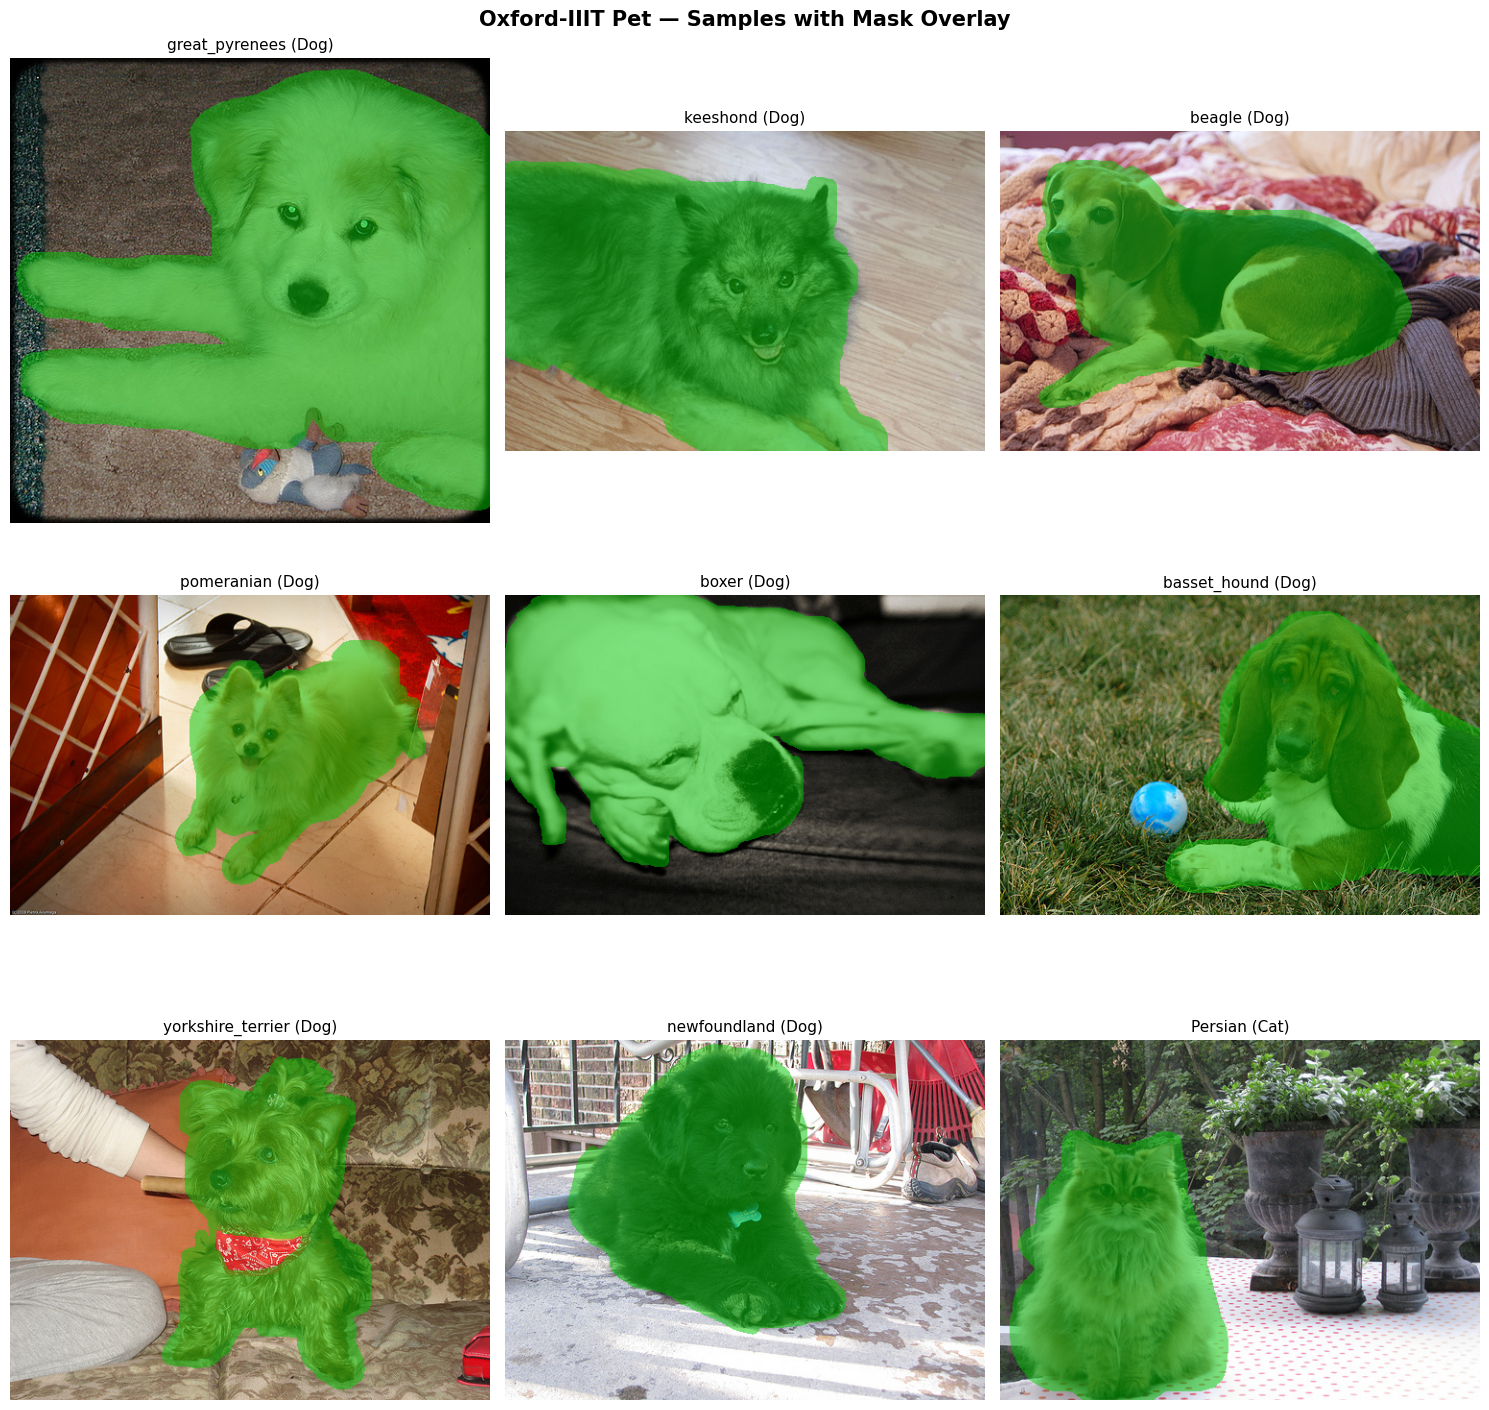

In [ ]:
def plot_3x3_grid(dataframe, seed=SEED):
    random.seed(seed)
    indices=random.sample(range(len(dataframe)),9)
    fig,axes=plt.subplots(3,3,figsize=(15,15))
    fig.suptitle('Oxford-IIIT Pet — Samples with Mask Overlay',fontsize=15,fontweight='bold')
    for ax,idx in zip(axes.flatten(),indices):
        row=dataframe.iloc[idx]
        img=np.array(Image.open(row['img_path']).convert('RGB'))
        mask=np.array(Image.fromarray(load_mask_binary(row['mask_path'])).resize(
            (img.shape[1],img.shape[0]),Image.NEAREST))
        ax.imshow(make_overlay(img,mask))
        ax.set_title(f"{row['breed']} ({row['species']})",fontsize=11)
        ax.axis('off')
    plt.tight_layout()
    plt.savefig(os.path.join(SAVE_DIR,'sample_grid.png'),dpi=120,bbox_inches='tight')
    plt.show()

plot_3x3_grid(df)


## Cell 4 — Train Base U-Net
> 🔁 **If Colab disconnects:** just run Cell 1 → Cell 2 → this cell again. It auto-resumes.

In [ ]:
unet_model=UNet(num_cls=NUM_CLASSES).to(DEVICE)
unet_history=run_training(unet_model,train_loader,val_loader,
    num_epochs=NUM_EPOCHS,lr=LR, # Changed back to full NUM_EPOCHS
    ckpt_path=UNET_CKPT,best_path=UNET_BEST)

🆕 Starting fresh — 30 epochs


  Train:   0%|          | 0/367 [00:00<?, ?it/s]/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
  Train:  14%|█▍        | 53/367 [1:28:39<8:50:06, 101.30s/it]

## Cell 5 — Base U-Net Training Curves

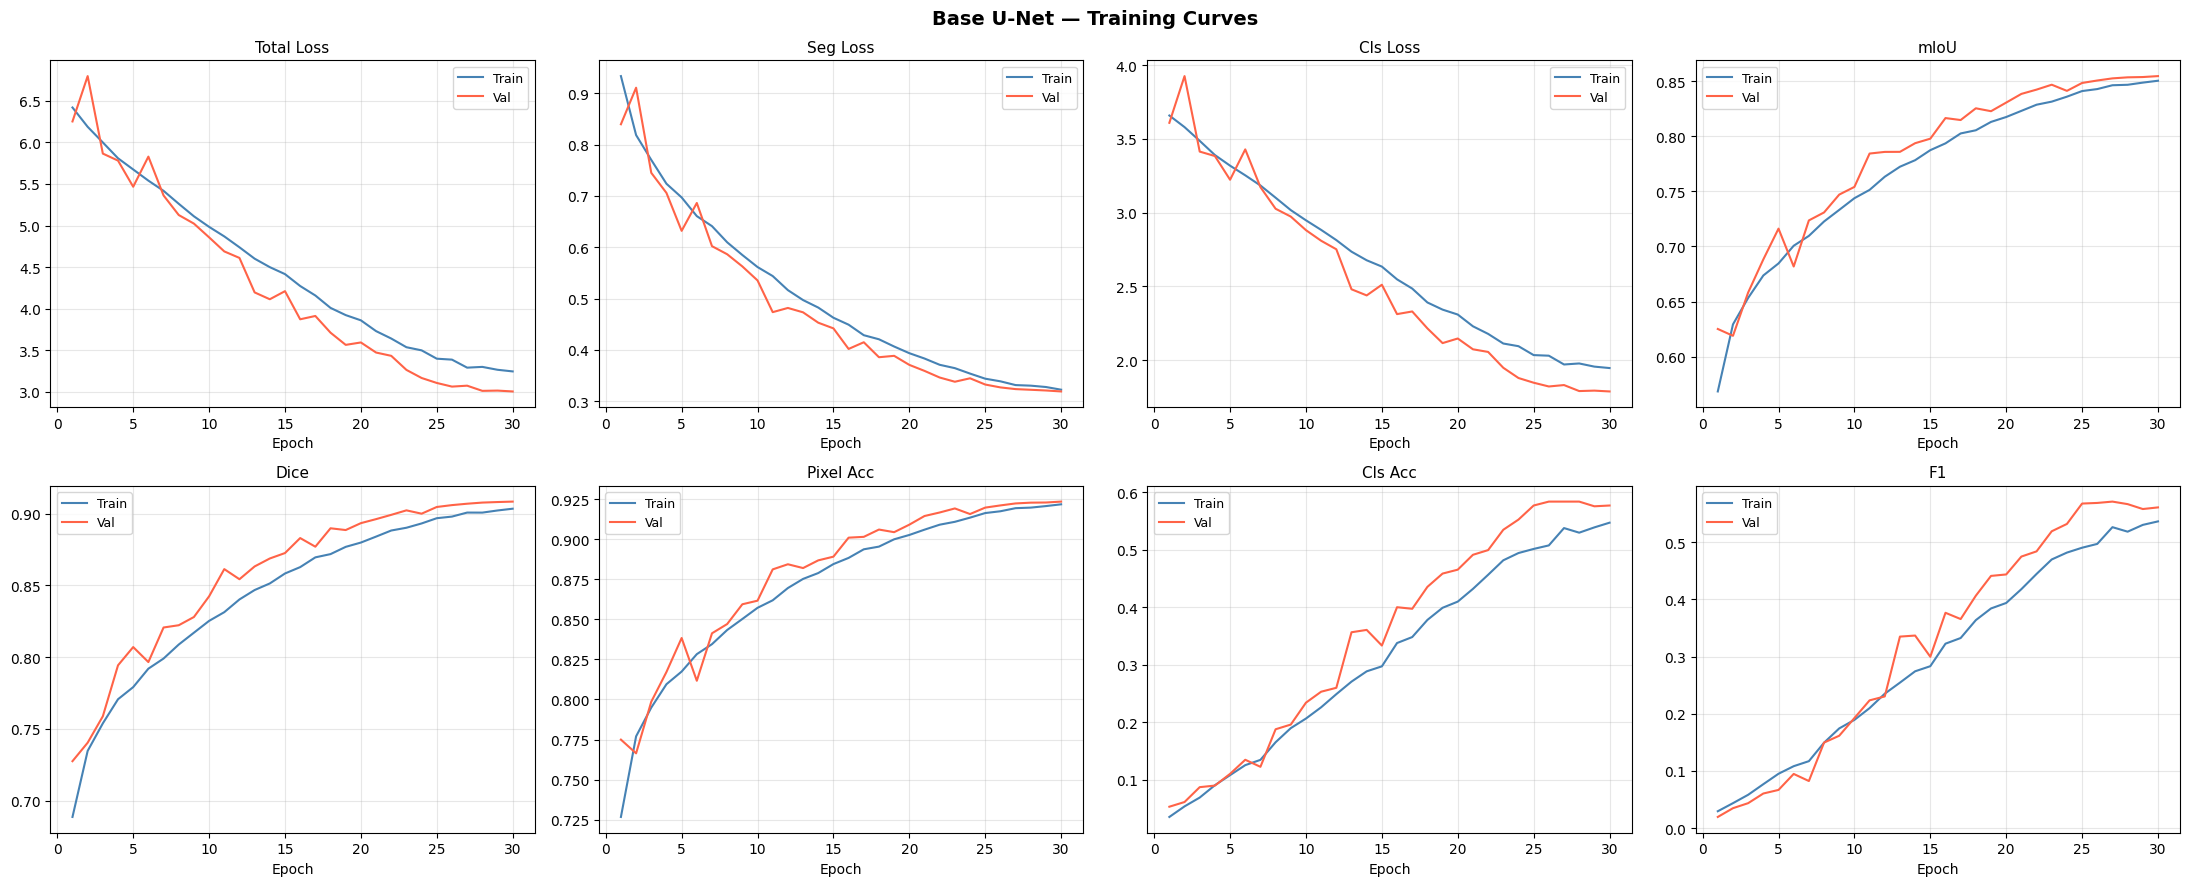

In [ ]:
if 'unet_history' not in dir() or not unet_history.get('train_loss'):
    unet_history=torch.load(UNET_CKPT,map_location='cpu',weights_only=False)['history']
    print(f'History reloaded — {len(unet_history["train_loss"])} epochs')
plot_history(unet_history,title='Base U-Net — Training Curves',
             save_path=os.path.join(SAVE_DIR,'unet_curves.png'))


## Cell 6 — Train Attention U-Net
> 🔁 **If Colab disconnects:** run Cell 1 → Cell 2 → this cell again. It auto-resumes.

In [ ]:
att_model=AttentionUNet(num_cls=NUM_CLASSES).to(DEVICE)
att_history=run_training(att_model,train_loader,val_loader,
    num_epochs=NUM_EPOCHS,lr=LR,
    ckpt_path=ATT_CKPT,best_path=ATT_BEST)


🔁 Resuming from checkpoint: att_checkpoint.pth
   Resumed from epoch 30  |  best mIoU so far: 0.8518
✅ Training already complete (30 epochs done).


## Cell 7 — Attention U-Net Training Curves

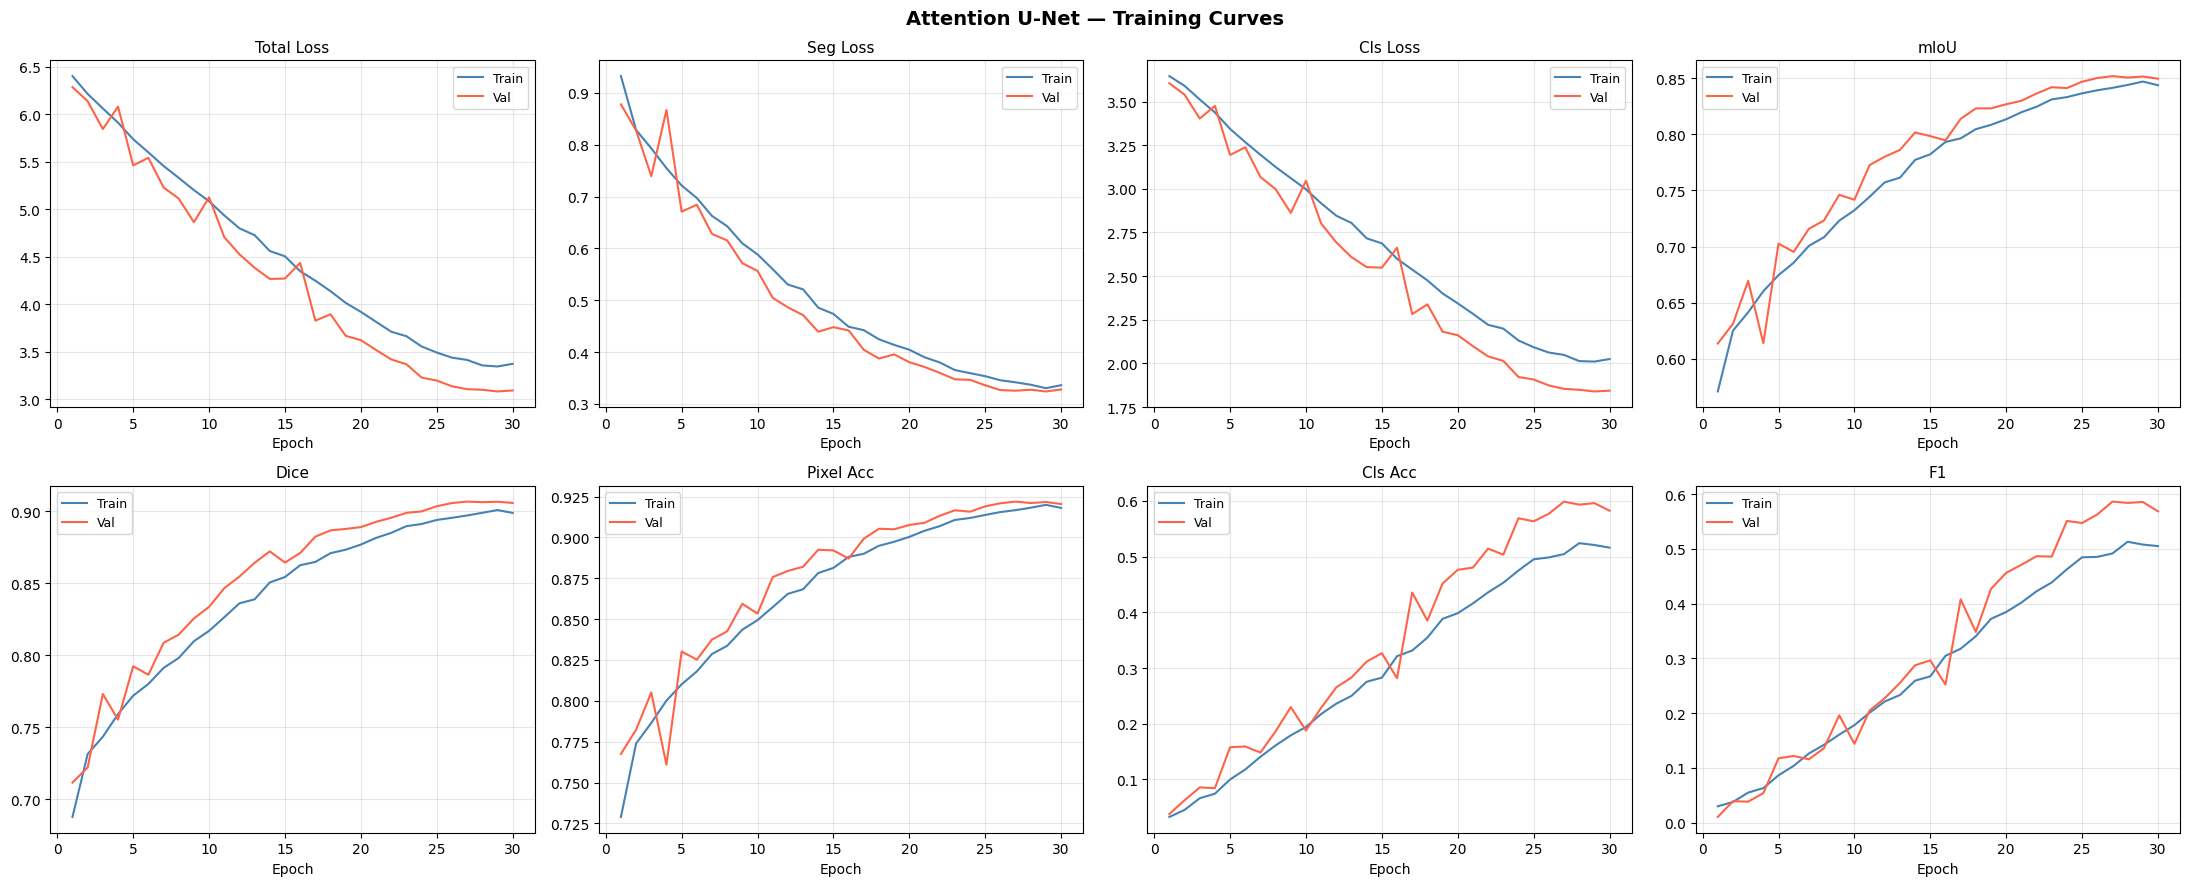

In [ ]:
if 'att_history' not in dir() or not att_history.get('train_loss'):
    att_history=torch.load(ATT_CKPT,map_location='cpu',weights_only=False)['history']
    print(f'History reloaded — {len(att_history["train_loss"])} epochs')
plot_history(att_history,title='Attention U-Net — Training Curves',
             save_path=os.path.join(SAVE_DIR,'att_unet_curves.png'))


## Cell 8 — Result Summaries (Train / Val / Test)

In [ ]:
if 'unet_model' not in dir(): unet_model=UNet(num_cls=NUM_CLASSES).to(DEVICE)
if 'att_model'  not in dir(): att_model =AttentionUNet(num_cls=NUM_CLASSES).to(DEVICE)
ALL_LOADERS={'Train':train_loader,'Val':val_loader,'Test':test_loader}

print('='*65+'\nBASE U-NET — Results\n'+'='*65)
unet_results=full_evaluation(unet_model,UNET_BEST,ALL_LOADERS)
display(unet_results)

print('\n'+'='*65+'\nATTENTION U-NET — Results\n'+'='*65)
att_results=full_evaluation(att_model,ATT_BEST,ALL_LOADERS)
display(att_results)


BASE U-NET — Results


,Loss,Seg Loss,Cls Loss,Pixel Acc,mIoU,Dice,Cls Acc,Precision,Recall,F1
Split,,,,,,,,,,
Train,2.9348,0.3108,1.7494,0.9253,0.8562,0.9072,0.6230,0.6194,0.6232,0.6099
Val,3.0019,0.3192,1.7884,0.9235,0.8545,0.9085,0.5769,0.5765,0.5768,0.5606
Test,2.8798,0.2750,1.7365,0.9336,0.8727,0.9220,0.6122,0.6177,0.6129,0.6011



ATTENTION U-NET — Results


,Loss,Seg Loss,Cls Loss,Pixel Acc,mIoU,Dice,Cls Acc,Precision,Recall,F1
Split,,,,,,,,,,
Train,3.0556,0.3224,1.8221,0.9217,0.8501,0.9033,0.5964,0.5927,0.5968,0.5845
Val,3.1066,0.3253,1.8542,0.9219,0.8518,0.9069,0.5986,0.5995,0.5988,0.5864
Test,2.9703,0.2876,1.7885,0.9297,0.8656,0.9175,0.5905,0.5932,0.5915,0.5734


## Cell 9 — Prediction Visualiser Function

In [ ]:
def predict_and_display(image_index,model,dataset,df_subset,
                        model_name='Model',device=DEVICE,save_path=None):
    model.eval()
    row=df_subset.reset_index(drop=True).iloc[image_index]
    orig=np.array(Image.open(row['img_path']).convert('RGB'))
    H,W=orig.shape[:2]
    true_mask=np.array(Image.fromarray(load_mask_binary(row['mask_path'])).resize((W,H),Image.NEAREST))
    img_t,mask_t,_=dataset[image_index]
    with torch.no_grad():
        sp,cp=model(img_t.unsqueeze(0).to(device))
    pred_small=(torch.sigmoid(sp)>0.5).squeeze().cpu().numpy().astype(np.uint8)
    pred_mask=np.array(Image.fromarray(pred_small*255).resize((W,H),Image.NEAREST))//255
    _,miou,_=seg_metrics(sp.cpu(),mask_t.unsqueeze(0))
    pred_id=cp.argmax(dim=1).item()
    true_breed=id2breed.get(int(row['class_id']),'?')
    pred_breed=id2breed.get(pred_id,'?')
    true_sp=id2species.get(int(row['class_id']),'?')
    pred_sp=id2species.get(pred_id,'?')
    fig,axes=plt.subplots(1,3,figsize=(15,5))
    fig.suptitle(
        f'Original class  - "{true_breed}" ({true_sp})\n'
        f'Predicted class - "{pred_breed}" ({pred_sp})\n'
        f'IoU - {miou*100:.1f}%',
        fontsize=12,fontfamily='monospace',y=1.04)
    axes[0].imshow(orig);                         axes[0].set_title('Original image');               axes[0].axis('off')
    axes[1].imshow(make_overlay(orig,true_mask));  axes[1].set_title('Image + True mask overlay');   axes[1].axis('off')
    axes[2].imshow(make_overlay(orig,pred_mask));  axes[2].set_title('Image + Predict mask overlay');axes[2].axis('off')
    plt.tight_layout()
    if save_path: plt.savefig(save_path,dpi=120,bbox_inches='tight')
    plt.show()
    print(f'[{model_name}] True:{true_breed}({true_sp}) | Pred:{pred_breed}({pred_sp}) | mIoU:{miou*100:.1f}%')

print('predict_and_display ready.')


predict_and_display ready.


### Cell 9a — Base U-Net: 3 Sample Predictions

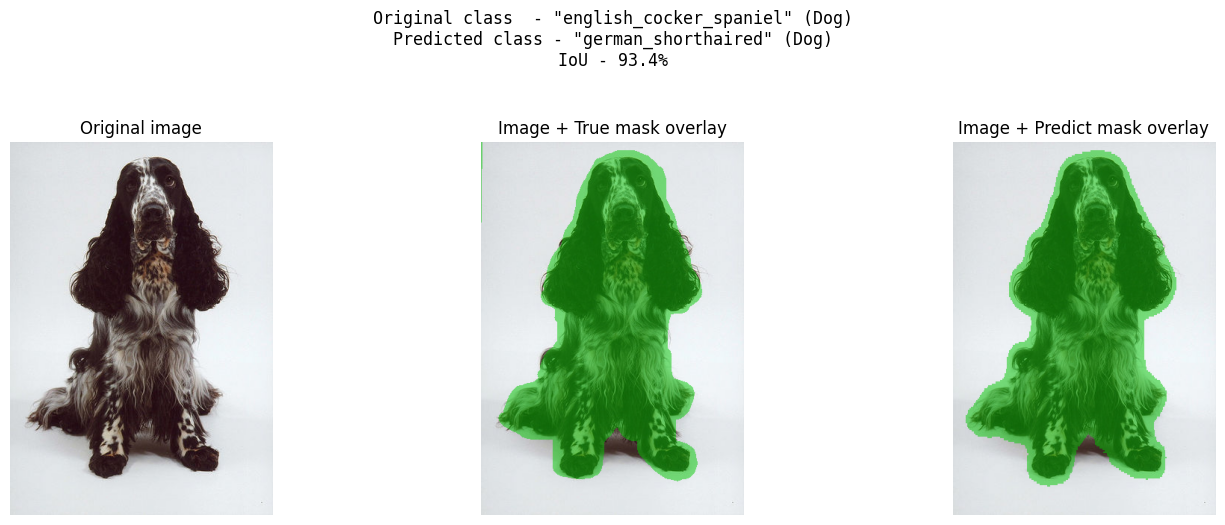

[Base U-Net] True:english_cocker_spaniel(Dog) | Pred:german_shorthaired(Dog) | mIoU:93.4%


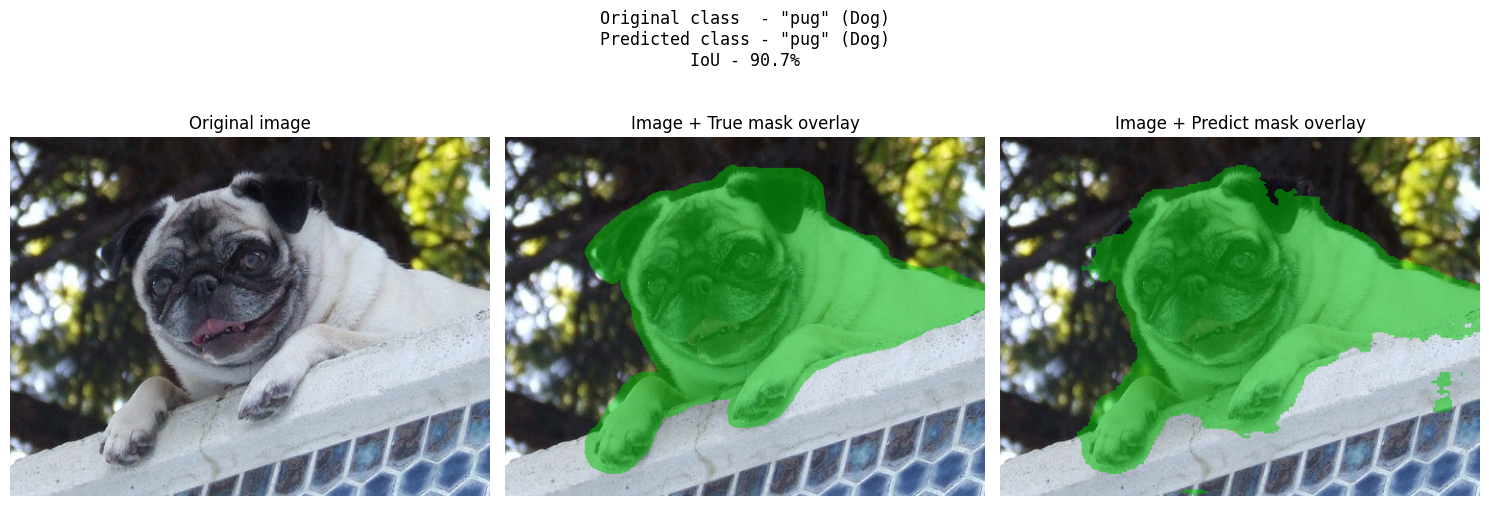

[Base U-Net] True:pug(Dog) | Pred:pug(Dog) | mIoU:90.7%


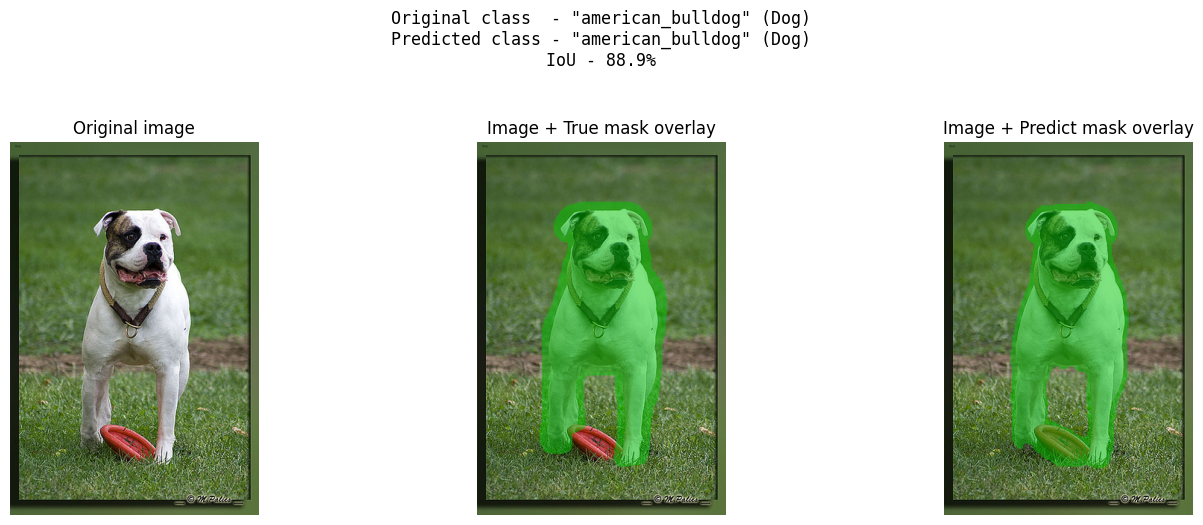

[Base U-Net] True:american_bulldog(Dog) | Pred:american_bulldog(Dog) | mIoU:88.9%


In [ ]:
if 'unet_model' not in dir(): unet_model=UNet(num_cls=NUM_CLASSES).to(DEVICE)
unet_model.load_state_dict(torch.load(UNET_BEST,map_location=DEVICE,weights_only=False))
for idx in random.sample(range(len(test_ds)),3):
    predict_and_display(idx,unet_model,test_ds,test_df,'Base U-Net',
                        save_path=os.path.join(SAVE_DIR,f'unet_pred_{idx}.png'))


### Cell 9b — Attention U-Net: 3 Sample Predictions

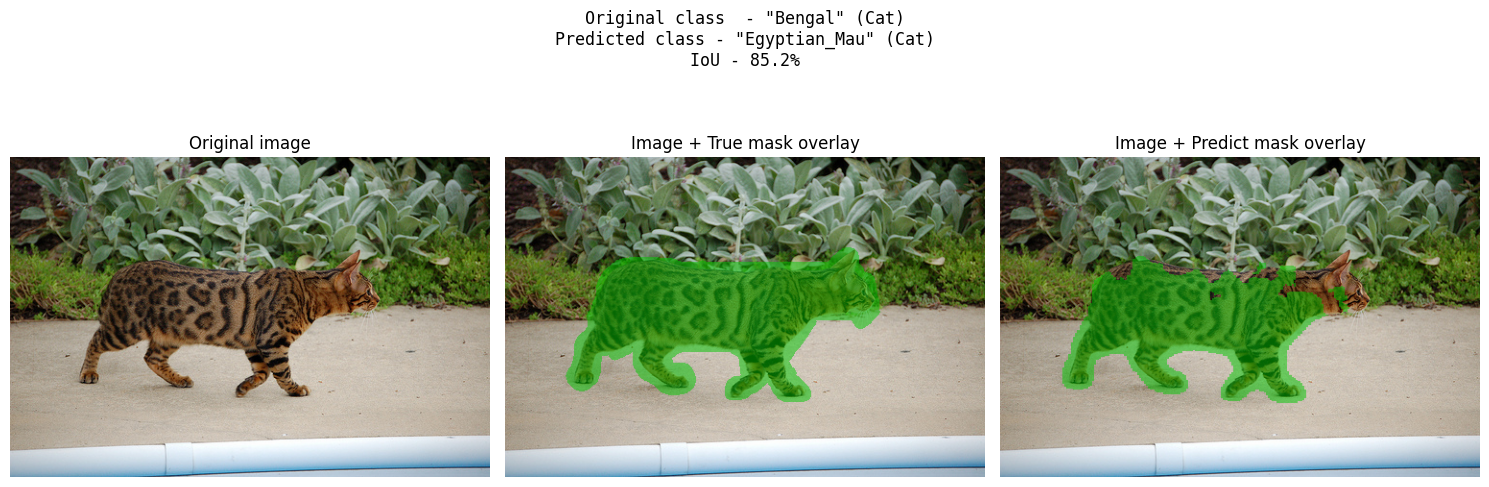

[Attention U-Net] True:Bengal(Cat) | Pred:Egyptian_Mau(Cat) | mIoU:85.2%


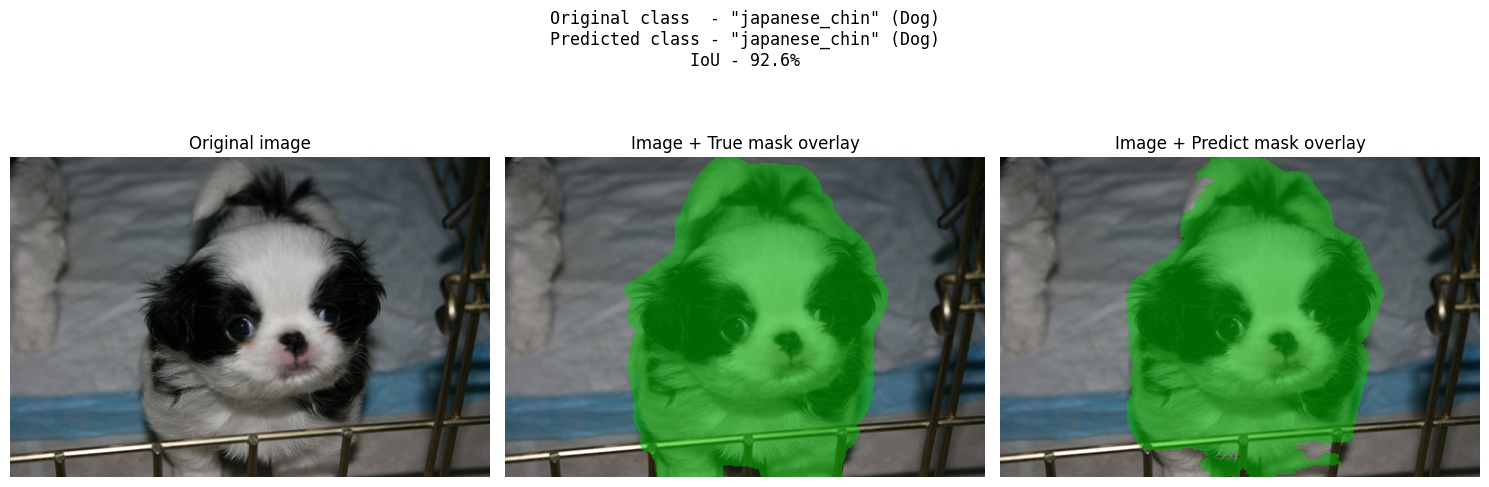

[Attention U-Net] True:japanese_chin(Dog) | Pred:japanese_chin(Dog) | mIoU:92.6%


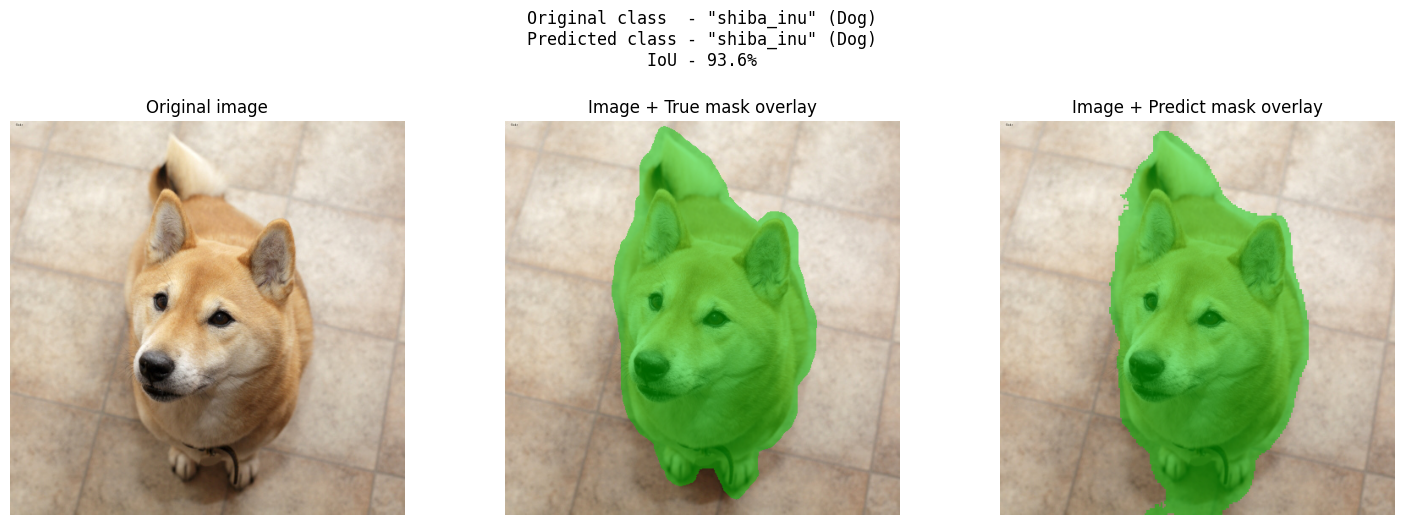

[Attention U-Net] True:shiba_inu(Dog) | Pred:shiba_inu(Dog) | mIoU:93.6%


In [ ]:
if 'att_model' not in dir(): att_model=AttentionUNet(num_cls=NUM_CLASSES).to(DEVICE)
att_model.load_state_dict(torch.load(ATT_BEST,map_location=DEVICE,weights_only=False))
for idx in random.sample(range(len(test_ds)),3):
    predict_and_display(idx,att_model,test_ds,test_df,'Attention U-Net',
                        save_path=os.path.join(SAVE_DIR,f'att_pred_{idx}.png'))


### Cell 9c — Interactive Demo (Viva / Demonstration)
*Change `TARGET_INDEX` and `USE_MODEL`, re-run only this cell.*

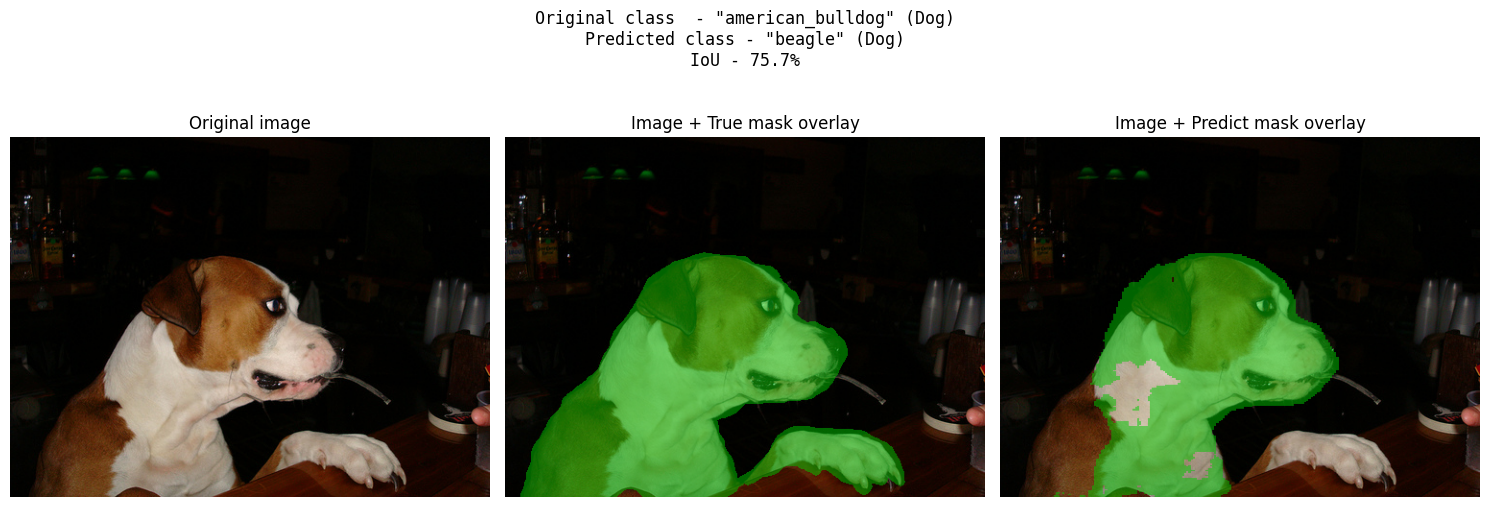

[ATTENTION] True:american_bulldog(Dog) | Pred:beagle(Dog) | mIoU:75.7%


In [ ]:
TARGET_INDEX = 0            # ← any index in test set
USE_MODEL    = 'attention'  # ← 'unet'  or  'attention'

if USE_MODEL=='unet':
    if 'unet_model' not in dir(): unet_model=UNet(num_cls=NUM_CLASSES).to(DEVICE)
    unet_model.load_state_dict(torch.load(UNET_BEST,map_location=DEVICE,weights_only=False))
    chosen=unet_model
else:
    if 'att_model' not in dir(): att_model=AttentionUNet(num_cls=NUM_CLASSES).to(DEVICE)
    att_model.load_state_dict(torch.load(ATT_BEST,map_location=DEVICE,weights_only=False))
    chosen=att_model

predict_and_display(TARGET_INDEX,chosen,test_ds,test_df,USE_MODEL.upper())


## Cell 10 — Model Comparison Bar Chart

=== Final Test-Set Comparison ===


,Loss,Seg Loss,Cls Loss,Pixel Acc,mIoU,Dice,Cls Acc,Precision,Recall,F1
Split,,,,,,,,,,
U-Net,2.8798,0.2750,1.7365,0.9336,0.8727,0.9220,0.6122,0.6177,0.6129,0.6011
Att-UNet,2.9703,0.2876,1.7885,0.9297,0.8656,0.9175,0.5905,0.5932,0.5915,0.5734


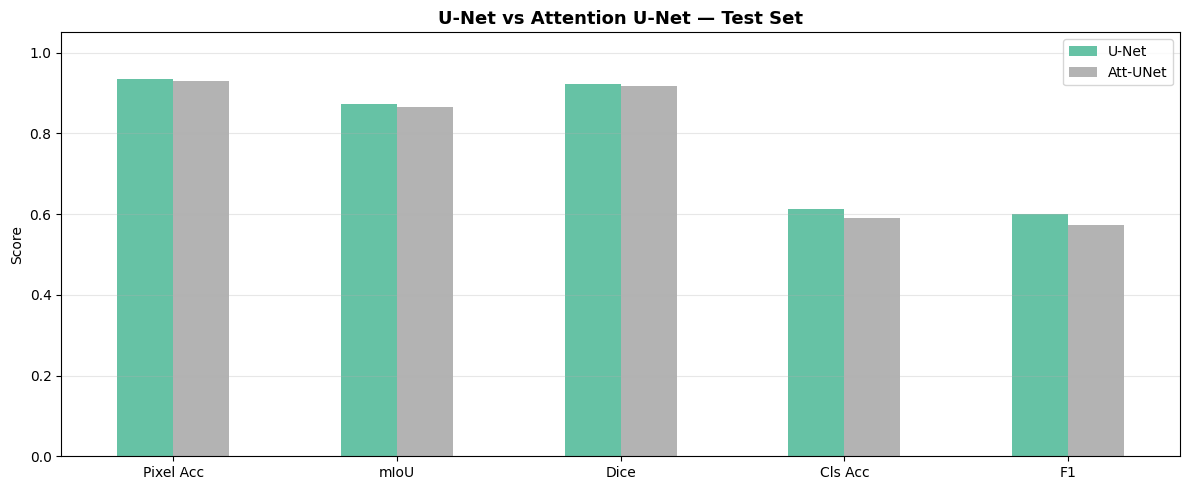

In [ ]:
cmp=pd.concat([unet_results.loc[['Test']].rename(index={'Test':'U-Net'}),
               att_results.loc[['Test']].rename(index={'Test':'Att-UNet'})])
print('=== Final Test-Set Comparison ==='); display(cmp)
cmp[['Pixel Acc','mIoU','Dice','Cls Acc','F1']].T.plot(
    kind='bar',figsize=(12,5),rot=0,colormap='Set2')
plt.title('U-Net vs Attention U-Net — Test Set',fontsize=13,fontweight='bold')
plt.ylabel('Score'); plt.ylim(0,1.05)
plt.legend(); plt.grid(axis='y',alpha=0.3); plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR,'model_comparison.png'),dpi=120,bbox_inches='tight')
plt.show()


---
## BONUS Task 1 — Classifier Architecture Comparison
*MobileNetV3-Small, EfficientNet-B0, DenseNet121 attached to U-Net bottleneck.*

In [ ]:
import torchvision.models as tvm

class UNetWithBackboneHead(nn.Module):
    def __init__(self,backbone_name,num_cls,features=[64,128,256,512]):
        super().__init__()
        f=features
        self.enc1=DoubleConv(3,f[0]); self.enc2=Down(f[0],f[1])
        self.enc3=Down(f[1],f[2]);    self.enc4=Down(f[2],f[3])
        self.bottleneck=Down(f[3],f[3]*2)
        self.dec4=Up(f[3]*2+f[3],f[3]); self.dec3=Up(f[3]+f[2],f[2])
        self.dec2=Up(f[2]+f[1],f[1]);   self.dec1=Up(f[1]+f[0],f[0])
        self.seg_head=nn.Conv2d(f[0],1,1)
        bn_ch=f[3]*2
        if backbone_name=='mobilenet_v3_small':
            bb=tvm.mobilenet_v3_small(weights=None)
            bb.features[0][0]=nn.Conv2d(bn_ch,16,3,2,1,bias=False)
            bb.classifier[3]=nn.Linear(bb.classifier[3].in_features,num_cls)
        elif backbone_name=='efficientnet_b0':
            bb=tvm.efficientnet_b0(weights=None)
            bb.features[0][0]=nn.Conv2d(bn_ch,32,3,2,1,bias=False)
            bb.classifier[1]=nn.Linear(bb.classifier[1].in_features,num_cls)
        elif backbone_name=='densenet121':
            bb=tvm.densenet121(weights=None)
            bb.features.conv0=nn.Conv2d(bn_ch,64,7,2,3,bias=False)
            bb.classifier=nn.Linear(bb.classifier.in_features,num_cls)
        self.cls_backbone=bb
    def forward(self,x):
        s1=self.enc1(x);s2=self.enc2(s1);s3=self.enc3(s2);s4=self.enc4(s3)
        b=self.bottleneck(s4); cls_out=self.cls_backbone(b)
        d4=self.dec4(b,s4);d3=self.dec3(d4,s3);d2=self.dec2(d3,s2);d1=self.dec1(d2,s1)
        return self.seg_head(d1),cls_out

bonus_arch_results={}
for arch in ['mobilenet_v3_small','efficientnet_b0','densenet121']:
    b_ckpt=os.path.join(SAVE_DIR,f'bonus_{arch}_ckpt.pth')
    b_best=os.path.join(SAVE_DIR,f'bonus_{arch}_best.pth')
    print(f'\n{"="*55}\nTraining U-Net + {arch}\n{"="*55}')
    bm=UNetWithBackboneHead(arch,NUM_CLASSES).to(DEVICE)
    run_training(bm,train_loader,val_loader,num_epochs=20,lr=LR,ckpt_path=b_ckpt,best_path=b_best)
    res=full_evaluation(bm,b_best,{'Test':test_loader})
    bonus_arch_results[arch]=res; print(res)

bonus_summary=pd.concat([v.rename(index={'Test':k}) for k,v in bonus_arch_results.items()])
print('\n=== Bonus Task 1 — Classifier Architecture Comparison ==='); display(bonus_summary)



Training U-Net + mobilenet_v3_small
🆕 Starting fresh — 20 epochs


Ep 001/20 | Loss 6.4244/6.2726 | mIoU 0.5704/0.6117 | Dice 0.6875/0.7392 | PixAcc 0.7292/0.7600 | ClsAcc 0.0291/0.0272 | F1 0.0248/0.0014
  ✔ Best saved → bonus_mobilenet_v3_small_best.pth (132.6 MB)  mIoU=0.6117
  💾 Checkpoint saved  Ep 1/20  (397.5 MB)


Ep 002/20 | Loss 6.3346/6.6667 | mIoU 0.5913/0.5822 | Dice 0.7031/0.7035 | PixAcc 0.7469/0.7390 | ClsAcc 0.0298/0.0354 | F1 0.0217/0.0084
  💾 Checkpoint saved  Ep 2/20  (397.5 MB)


Ep 003/20 | Loss 6.3384/6.3394 | mIoU 0.5847/0.5719 | Dice 0.6996/0.7236 | PixAcc 0.7419/0.7277 | ClsAcc 0.0301/0.0395 | F1 0.0222/0.0142
  💾 Checkpoint saved  Ep 3/20  (397.5 MB)


Ep 004/20 | Loss 6.3324/6.4143 | mIoU 0.5897/0.5995 | Dice 0.6990/0.6991 | PixAcc 0.7471/0.7568 | ClsAcc 0.0291/0.0286 | F1 0.0183/0.0082
  💾 Checkpoint saved  Ep 4/20  (397.5 MB)


Ep 005/20 | Loss 6.3121/6.3157 | mIoU 0.6004/0.5933 | Dice 0.7098/0.6809 | PixAcc 0.7550/0.7559 | ClsAcc 0.0284/0.0286 | F1 0.0207/0.0047
  💾 Checkpoint saved  Ep 5/20  (397.5 MB)


Ep 006/20 | Loss 6.3066/6.2984 | mIoU 0.6027/0.6081 | Dice 0.7111/0.6968 | PixAcc 0.7570/0.7664 | ClsAcc 0.0264/0.0299 | F1 0.0140/0.0063
  💾 Checkpoint saved  Ep 6/20  (397.5 MB)


Ep 007/20 | Loss 6.2855/6.2695 | mIoU 0.6081/0.6191 | Dice 0.7145/0.7337 | PixAcc 0.7615/0.7677 | ClsAcc 0.0283/0.0313 | F1 0.0153/0.0098
  ✔ Best saved → bonus_mobilenet_v3_small_best.pth (132.6 MB)  mIoU=0.6191
  💾 Checkpoint saved  Ep 7/20  (397.5 MB)


Ep 008/20 | Loss 6.2426/6.2373 | mIoU 0.6229/0.6295 | Dice 0.7281/0.7375 | PixAcc 0.7726/0.7766 | ClsAcc 0.0329/0.0354 | F1 0.0203/0.0058
  ✔ Best saved → bonus_mobilenet_v3_small_best.pth (132.6 MB)  mIoU=0.6295
  💾 Checkpoint saved  Ep 8/20  (397.5 MB)


  Train:  28%|██▊       | 101/367 [01:22<03:26,  1.29it/s]

## BONUS Task 2 — Augmentation Ablation Study

In [ ]:
no_aug_tf=A.Compose([A.Resize(IMG_SIZE,IMG_SIZE),
    A.Normalize(mean=IMAGENET_MEAN,std=IMAGENET_STD),ToTensorV2()])
train_ds_na=PetDataset(train_df,transform=no_aug_tf)
loader_na=DataLoader(train_ds_na,batch_size=BATCH_SIZE,shuffle=True,num_workers=0,pin_memory=True)

noaug_ckpt=os.path.join(SAVE_DIR,'unet_noaug_ckpt.pth')
noaug_best=os.path.join(SAVE_DIR,'unet_noaug_best.pth')
print('Training WITHOUT augmentation (20 epochs)...')
unet_na=UNet(num_cls=NUM_CLASSES).to(DEVICE)
hist_na=run_training(unet_na,loader_na,val_loader,num_epochs=20,lr=LR,
                     ckpt_path=noaug_ckpt,best_path=noaug_best)

if 'unet_model' not in dir(): unet_model=UNet(num_cls=NUM_CLASSES).to(DEVICE)
res_na =full_evaluation(unet_na,   noaug_best,{'Test':test_loader})
res_aug=full_evaluation(unet_model,UNET_BEST, {'Test':test_loader})

aug_cmp=pd.concat([res_na.rename(index={'Test':'Without Augmentation'}),
                   res_aug.rename(index={'Test':'With Augmentation'})])
print('\n=== Bonus Task 2 — Augmentation Ablation ==='); display(aug_cmp)

delta=res_aug.copy()
for col in delta.columns: delta[col]=res_aug[col]-res_na[col]
delta.index=['Delta (Aug minus NoAug)']
print('\nImprovement:'); display(delta)

aug_h=torch.load(UNET_CKPT,map_location='cpu',weights_only=False)['history']
plt.figure(figsize=(9,4))
plt.plot(hist_na['val_miou'],        label='No Aug',        color='tomato',   lw=2)
plt.plot(aug_h['val_miou'][:20],     label='With Aug',      color='steelblue',lw=2)
plt.title('Val mIoU: With vs Without Augmentation',fontsize=12,fontweight='bold')
plt.xlabel('Epoch'); plt.ylabel('mIoU'); plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR,'augmentation_ablation.png'),dpi=120); plt.show()


---
*End of CSE428 Spring 26 Project Notebook*